# Experiment E — teach the model real-world pothole photos (incl. water-filled)

**Idea:** fine-tune the current best model (`yolov8s_all_ft_india`) on a **mix** of
- the India RDD2022 training images (all 4 classes, so it does **not forget cracks**), and
- a public, already-labelled **pothole photo dataset** (665 photos, many with water-filled potholes; Kaggle "Pothole Detection" by andrewmvd, DbCL licence), mapped to our `pothole` class.

**Runtime:** T4 GPU. Run cells top to bottom. Total ≈ 1 hour.
If Colab disconnects during training: run cells 1, 2, 3, then the **Resume** cell.

## 1. Startup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!pip install -q ultralytics

import glob, os, json, random, shutil, zipfile, urllib.request, yaml
import pandas as pd
from ultralytics import YOLO

PROJECT = '/content/drive/MyDrive/RDD_Project'
DATA = '/content/RDD2022/data'
if not os.path.exists(DATA):
    !unzip -q -o {PROJECT}/rdd2022_india.zip -d /content

with open(f'{DATA}/data.yaml') as f:
    names = yaml.safe_load(f)['names']
if isinstance(names, list):
    names = {i: n for i, n in enumerate(names)}
POTHOLE_ID = [k for k, v in names.items() if v == 'pothole'][0]

with open('/content/rdd_india.yaml', 'w') as f:
    yaml.safe_dump({'path': DATA, 'train': 'images/train', 'val': 'images/valid',
                    'test': 'images/test', 'names': names}, f, sort_keys=False)
print('Classes:', names, '| pothole id =', POTHOLE_ID)

Mounted at /content/drive
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Classes: {0: 'longitudinal_crack', 1: 'transverse_crack', 2: 'alligator_crack', 3: 'pothole'} | pothole id = 3


## 2. Get the pothole photo dataset and convert it to YOLO format
Downloaded once, then a converted copy is kept on Drive (`pothole_yolo.zip`, small).

In [ ]:
RAW = '/content/pothole_raw'
POT = '/content/pothole_yolo'
SAVED = f'{PROJECT}/pothole_yolo.zip'

if os.path.exists(SAVED):
    !unzip -q -o {SAVED} -d /content
    print('Restored converted pothole dataset from Drive')
else:
    url = 'https://automl-mm-bench.s3.amazonaws.com/object_detection/dataset/pothole.zip'
    print('Downloading', url)
    urllib.request.urlretrieve(url, '/content/pothole.zip')
    with zipfile.ZipFile('/content/pothole.zip') as z:
        z.extractall(RAW)

    # index every image by file name
    img_index = {}
    for p in glob.glob(f'{RAW}/**/*', recursive=True):
        if p.lower().endswith(('.jpg', '.jpeg', '.png')):
            img_index[os.path.basename(p)] = p

    jsons = glob.glob(f'{RAW}/**/*.json', recursive=True)
    print('Annotation files found:', jsons)
    if not jsons:
        raise RuntimeError('No COCO .json found - send a screenshot of the folder listing below')

    counts = {}
    for jp in jsons:
        low = os.path.basename(jp).lower()
        split = 'train' if 'train' in low else 'val' if 'val' in low else 'test' if 'test' in low else None
        if split is None:
            print('Skipping', jp); continue
        coco = json.load(open(jp))
        anns = {}
        for a in coco['annotations']:
            anns.setdefault(a['image_id'], []).append(a['bbox'])
        os.makedirs(f'{POT}/images/{split}', exist_ok=True)
        os.makedirs(f'{POT}/labels/{split}', exist_ok=True)
        n = 0
        for im in coco['images']:
            src = img_index.get(os.path.basename(im['file_name']))
            if src is None:
                continue
            W, H = im['width'], im['height']
            stem = 'pothole_' + os.path.splitext(os.path.basename(src))[0]
            shutil.copy(src, f'{POT}/images/{split}/{stem}.jpg' if src.lower().endswith(('.jpg', '.jpeg'))
                        else f'{POT}/images/{split}/{stem}.png')
            lines = []
            for x, y, w, h in anns.get(im['id'], []):
                if w <= 1 or h <= 1:
                    continue
                lines.append(f'{POTHOLE_ID} {(x + w/2)/W:.6f} {(y + h/2)/H:.6f} {w/W:.6f} {h/H:.6f}')
            open(f'{POT}/labels/{split}/{stem}.txt', 'w').write('\n'.join(lines))
            n += 1
        counts[split] = counts.get(split, 0) + n
    print('Converted images per split:', counts)

    %cd /content
    !zip -qr {SAVED} pothole_yolo
    print('Saved converted dataset to Drive')

for s in ['train', 'val', 'test']:
    print(s, len(glob.glob(f'{POT}/images/{s}/*')), 'images')
# if the download has no separate test split, use val for testing
POT_TEST = 'test' if glob.glob(f'{POT}/images/test/*') else 'val'
print('Pothole photos used for testing: images/' + POT_TEST)

Annotation files found: ['/content/pothole_raw/pothole/Annotations/usersplit_val_cocoformat.json', '/content/pothole_raw/pothole/Annotations/usersplit_test_cocoformat.json', '/content/pothole_raw/pothole/Annotations/usersplit_train_cocoformat.json']
Converted images per split: {'val': 133, 'test': 133, 'train': 399}
/content
Saved converted dataset to Drive
train 399 images
val 133 images
test 133 images
Pothole photos used for testing: images/test


## 3. Look at a few pothole photos with their labels (quick sanity check)

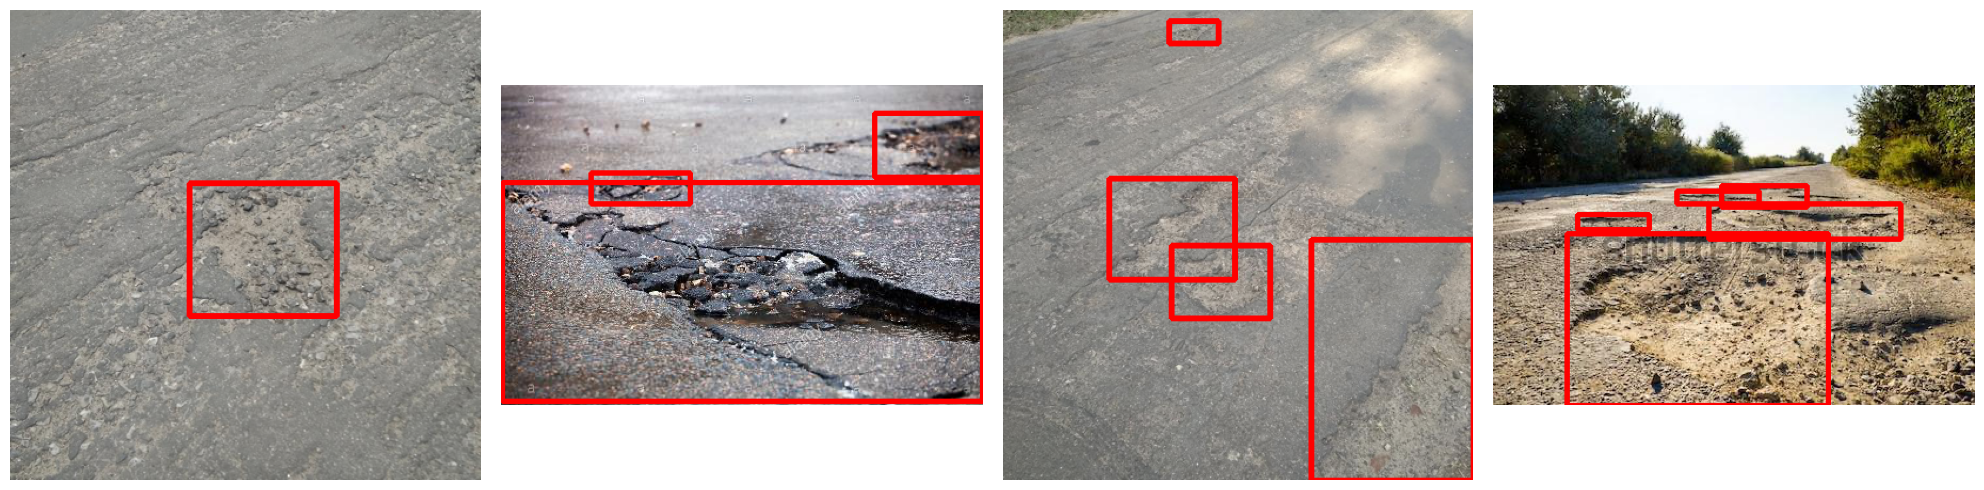

In [ ]:
import cv2, matplotlib.pyplot as plt
samples = random.Random(1).sample(glob.glob(f'{POT}/images/train/*'), 4)
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, p in zip(axes, samples):
    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB); h, w = img.shape[:2]
    lp = p.replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt'
    for line in open(lp).read().split('\n'):
        if not line.strip(): continue
        c, xc, yc, bw, bh = map(float, line.split())
        cv2.rectangle(img, (int((xc-bw/2)*w), int((yc-bh/2)*h)), (int((xc+bw/2)*w), int((yc+bh/2)*h)), (255, 0, 0), 3)
    ax.imshow(img); ax.axis('off')
plt.tight_layout(); plt.show()

## 4. Build the mixed training set and train (≈ 40–60 min)
Pothole photos are listed 4× so the model sees them often enough next to ~5,400 India images.
Validation = India valid + pothole val, so the saved `best.pt` must be good at **both**.

In [ ]:
india_train = sorted(glob.glob(f'{DATA}/images/train/**/*.jpg', recursive=True))
india_val   = sorted(glob.glob(f'{DATA}/images/valid/**/*.jpg', recursive=True))
pot_train   = sorted(glob.glob(f'{POT}/images/train/*'))
pot_val     = sorted(glob.glob(f'{POT}/images/val/*'))

open('/content/train_mix.txt', 'w').write('\n'.join(india_train + pot_train * 4))
open('/content/val_mix.txt', 'w').write('\n'.join(india_val + pot_val))
with open('/content/mix.yaml', 'w') as f:
    yaml.safe_dump({'train': '/content/train_mix.txt', 'val': '/content/val_mix.txt', 'names': names}, f, sort_keys=False)
with open('/content/pothole_test.yaml', 'w') as f:
    yaml.safe_dump({'path': POT, 'train': 'images/train', 'val': f'images/{POT_TEST}', 'names': names}, f, sort_keys=False)

print(f'Train: {len(india_train)} India + {len(pot_train)} pothole photos (x4)')
print(f'Val:   {len(india_val)} India + {len(pot_val)} pothole photos')

Train: 5368 India + 399 pothole photos (x4)
Val:   1172 India + 133 pothole photos


In [ ]:
model = YOLO(f'{PROJECT}/runs/yolov8s_all_ft_india/weights/best.pt')   # current best model
model.train(
    data='/content/mix.yaml',
    epochs=20, imgsz=640, batch=16, patience=10,
    optimizer='AdamW', lr0=0.001,
    project=f'{PROJECT}/runs', name='yolov8s_final_mix', exist_ok=True,
)

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/mix.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/RDD_Project/runs/yolov8s_all_ft_india/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x78e9101479d0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0

**Resume** (only if Colab disconnected — run cells 1, 2 and the train-list cell first):

In [ ]:
YOLO(f'{PROJECT}/runs/yolov8s_final_mix/weights/last.pt').train(resume=True)

## 5. Before vs after: India test set AND pothole photo test set

In [ ]:
models = {
    'Before (yolov8s_all_ft_india)': f'{PROJECT}/runs/yolov8s_all_ft_india/weights/best.pt',
    'After  (yolov8s_final_mix)':    f'{PROJECT}/runs/yolov8s_final_mix/weights/best.pt',
}
rows = []
for label, w in models.items():
    m = YOLO(w)
    india = m.val(data='/content/rdd_india.yaml', split='test', verbose=False,
                  project=f'{PROJECT}/runs', name=os.path.basename(os.path.dirname(os.path.dirname(w))) + '_test', exist_ok=True)
    pot = m.val(data='/content/pothole_test.yaml', split='val', verbose=False,
                project=f'{PROJECT}/runs', name=os.path.basename(os.path.dirname(os.path.dirname(w))) + '_pothole_photos', exist_ok=True)
    ap = dict(zip(india.ap_class_index, india.box.ap50))
    rows.append({
        'Model': label,
        'India test mAP@0.5': round(india.box.map50, 4),
        **{f'India {names[i]}': round(float(ap.get(i, 0.0)), 4) for i in names},
        'Pothole photos mAP@0.5': round(pot.box.map50, 4),
        'Pothole photos recall': round(pot.box.mr, 4),
    })
res = pd.DataFrame(rows)
res.to_csv(f'{PROJECT}/experiment_E_results.csv', index=False)
display(res.T)

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 36.1±9.7 MB/s, size: 67.3 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/RDD2022/data/labels/test/shard_000... 1166 images, 725 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1166/1166 811.8it/s 1.4s
val: New cache created: /content/RDD2022/data/labels/test/shard_000.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 73/73 4.0it/s 18.5s
                   all       1166        723      0.418      0.427      0.365      0.173
Speed: 1.2ms preprocess, 11.5ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /content/drive/MyDrive/RDD_Project/runs/yolov8s_all_ft_india_te

,0,1
Model,Before (yolov8s_all_ft_india),After (yolov8s_final_mix)
India test mAP@0.5,0.3651,0.3781
India longitudinal_crack,0.3505,0.3709
India transverse_crack,0.0799,0.0778
India alligator_crack,0.6403,0.6507
India pothole,0.3898,0.413
Pothole photos mAP@0.5,0.0029,0.7661
Pothole photos recall,0.0442,0.6991


## 6. See it on a few pothole test photos (saved to Drive for the report)

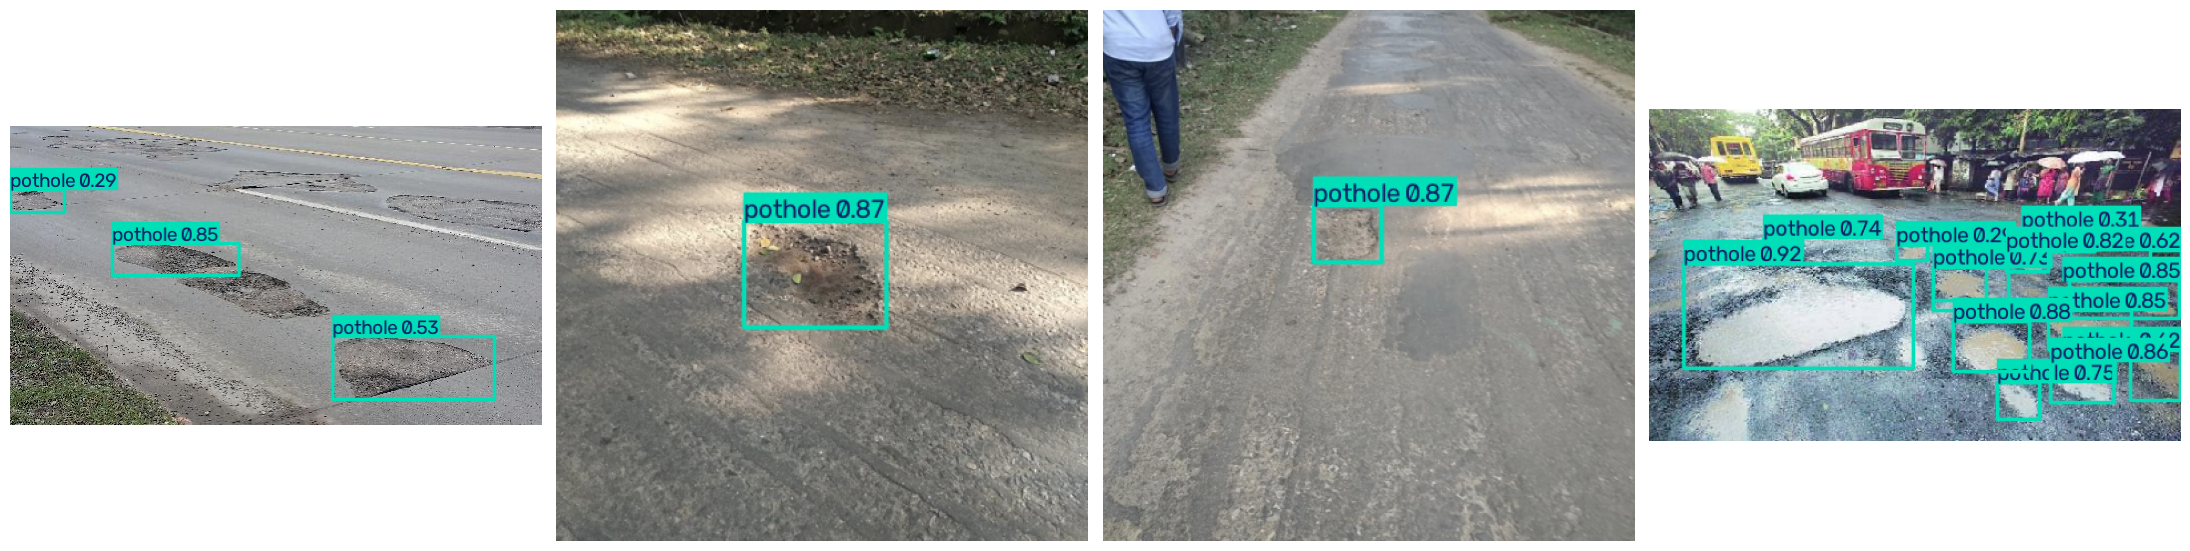

8 test photos copied to Drive: RDD_Project/demo_potholes (use them in the app)


In [ ]:
best = YOLO(f'{PROJECT}/runs/yolov8s_final_mix/weights/best.pt')
os.makedirs(f'{PROJECT}/demo_potholes', exist_ok=True)
picks = random.Random(5).sample(glob.glob(f'{POT}/images/{POT_TEST}/*'), 8)
for p in picks:
    shutil.copy(p, f'{PROJECT}/demo_potholes/')
res = best.predict(picks[:4], conf=0.25, verbose=False)
fig, axes = plt.subplots(1, 4, figsize=(22, 6))
for ax, r in zip(axes, res):
    ax.imshow(r.plot()[:, :, ::-1]); ax.axis('off')
plt.tight_layout(); plt.savefig(f'{PROJECT}/pothole_photo_predictions.png', dpi=150); plt.show()
print('8 test photos copied to Drive: RDD_Project/demo_potholes (use them in the app)')